# Adding a land-sea mask


In [1]:
import Pkg
Pkg.activate("../")
Pkg.instantiate()
using Makie
using CairoMakie
using GeoMakie
using NCDatasets
using GeoDatasets
using JupyterFormatter
enable_autoformat()

  Activating project at `~/Projects/maps-with-makie`
Precompiling packages...
 106.8 s  ✓ Makie
   4.1 s  ✓ IntervalArithmetic → IntervalArithmeticMakieExt
   4.2 s  ✓ GeoJSON → GeoJSONMakieExt
   4.3 s  ✓ GeoInterface → GeoInterfaceMakieExt
   4.7 s  ✓ Rasters → RastersMakieExt
   4.7 s  ✓ ArchGDAL → ArchGDALMakieExt
   4.8 s  ✓ DimensionalData → DimensionalDataMakieExt
   4.8 s  ✓ IntervalSets → IntervalSetsMakieExt
   5.0 s  ✓ Polynomials → PolynomialsMakieExt
   5.1 s  ✓ GeometryOps → GeometryOpsMakieExt
   5.7 s  ✓ GeoMakie
  29.1 s  ✓ CairoMakie
  12 dependencies successfully precompiled in 141 seconds. 477 already precompiled.
[ Info: Precompiling ShapefileMakieExt [d27b357f-fe25-5c9a-a979-246d20d4d1e4] (caches not reused: 1 for different dependency version already loaded, 4 for different Julia build configuration)
Precompiling packages...
   3.4 s  ✓ ShapefileMakieExt (serial)
  1 dependency successfully precompiled in 5 seconds


1-element Vector{Function}:
 format_current_cell (generic function with 1 method)

(-179.95833333333334:0.08333333333333333:179.95833333333334, -89.95833333333333:0.08333333333333333:89.95833333333333, UInt8[0x01 0x01 … 0x00 0x00; 0x01 0x01 … 0x00 0x00; … ; 0x01 0x01 … 0x00 0x00; 0x01 0x01 … 0x00 0x00])

In [5]:
domain = [8.67615, 8.8417, 42.5372, 42.6268]

4-element Vector{Float64}:
  8.67615
  8.8417
 42.5372
 42.6268

In [13]:
function subset_mask(lon, lat, data, domain)
    goodlon = findall(domain[1] .<= lon .<= domain[2])
    goodlat = findall(domain[3] .<= lat .<= domain[4])
    lon_mask = @view(lon[goodlon])
    lat_mask = @view(lat[goodlat])
    mask = @view(data[goodlon, goodlat])
    return lon_mask, lat_mask, mask
end

subset_mask (generic function with 1 method)

In [14]:
function plot_mask(lon_mask, lat_mask, mask)
    fig = Figure()
    ax = Axis(fig[1, 1])
    heatmap!(lon_mask, lat_mask, mask)
    return fig::Figure
end

plot_mask (generic function with 1 method)

[ Info: Downloading file 'lsmask_1.25min_l.bin' from 'https://raw.githubusercontent.com/matplotlib/basemap/v1.2.2rel/lib/mpl_toolkits/basemap/data/lsmask_1.25min_l.bin' with cURL.


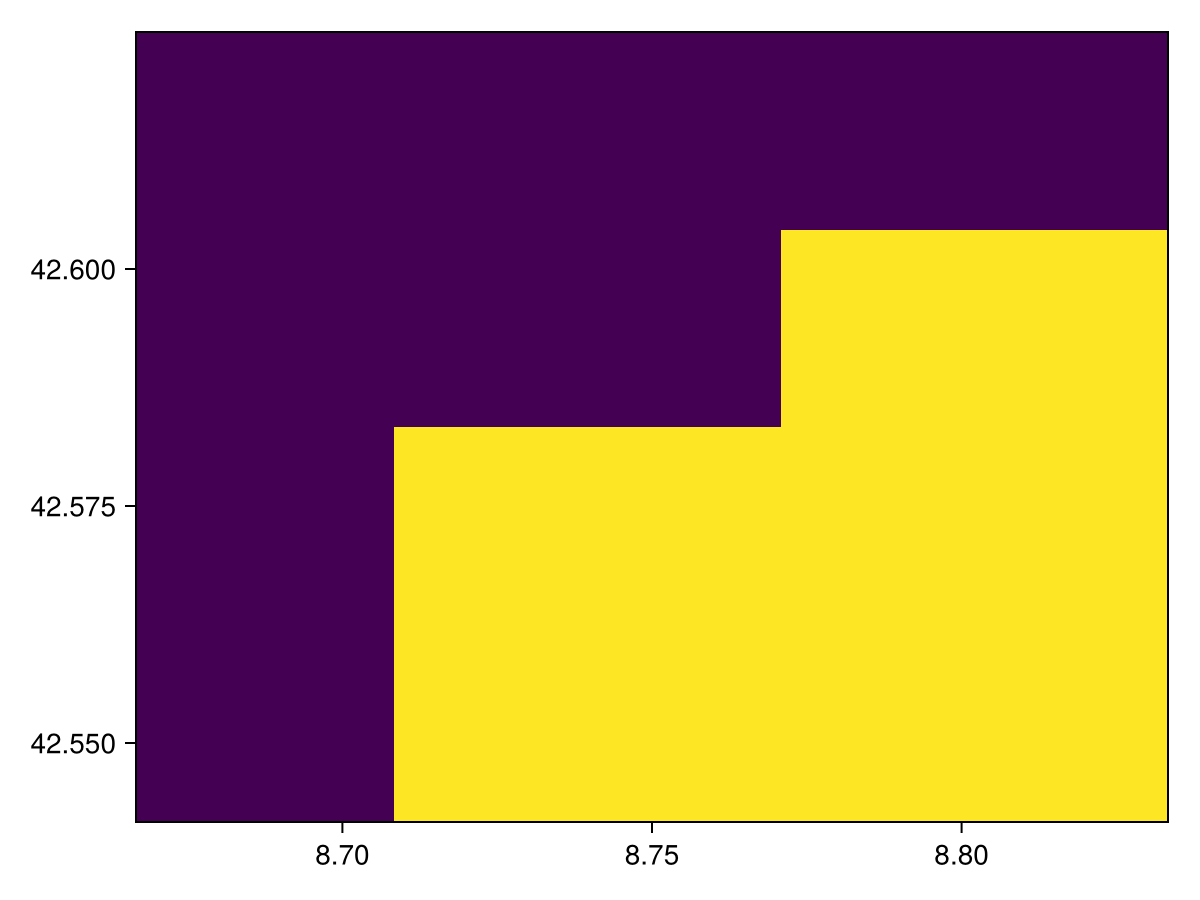

In [19]:
lon, lat, data = GeoDatasets.landseamask(; resolution = 'l', grid = 1.25)
lon_mask, lat_mask, mask = subset_mask(lon, lat, data, domain)
plot_mask(lon_mask, lat_mask, mask)

[ Info: Downloading file 'lsmask_1.25min_i.bin' from 'https://raw.githubusercontent.com/matplotlib/basemap/v1.2.2rel/lib/mpl_toolkits/basemap/data/lsmask_1.25min_i.bin' with cURL.


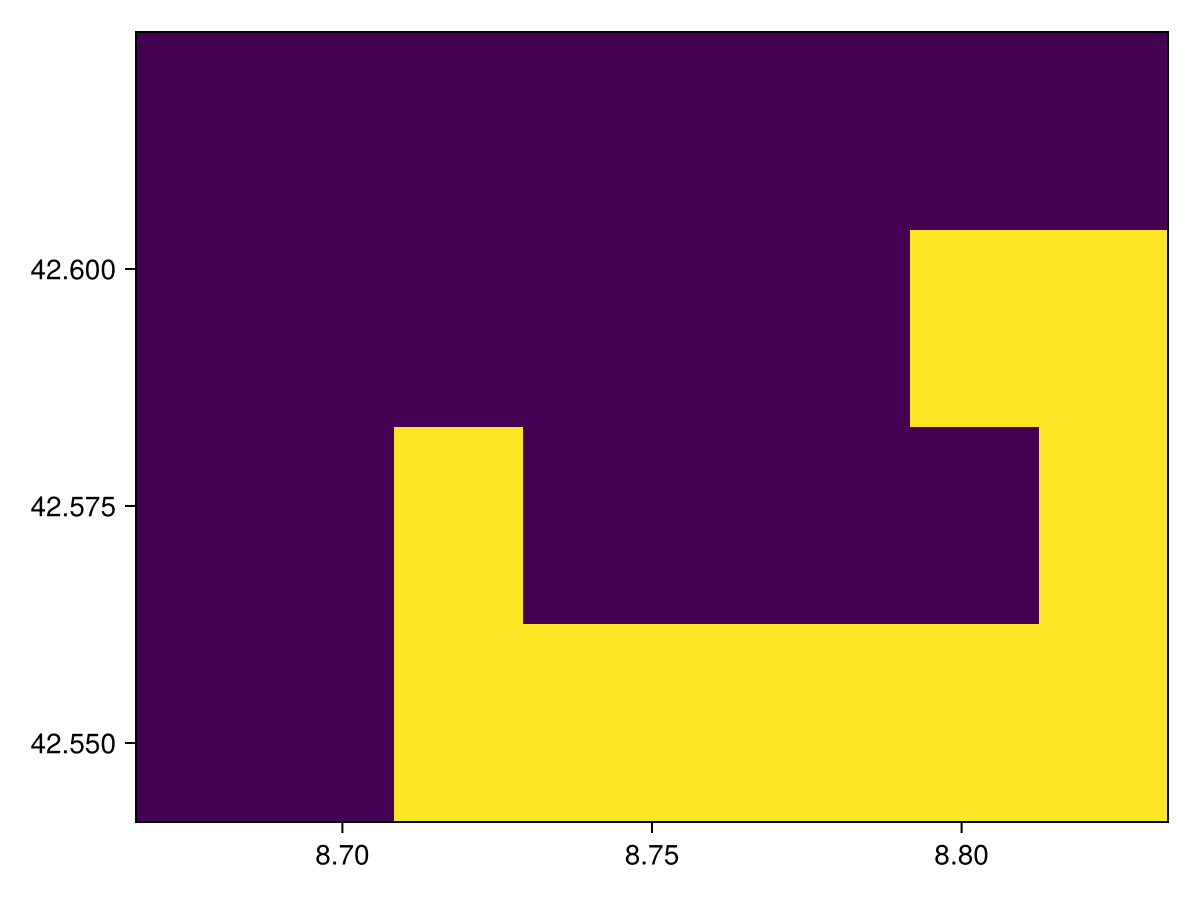

In [20]:
lon, lat, data = GeoDatasets.landseamask(; resolution = 'i', grid = 1.25)
lon_mask, lat_mask, mask = subset_mask(lon, lat, data, domain)
plot_mask(lon_mask, lat_mask, mask)

[ Info: Downloading file 'lsmask_1.25min_h.bin' from 'https://raw.githubusercontent.com/matplotlib/basemap/v1.2.2rel/lib/mpl_toolkits/basemap/data/lsmask_1.25min_h.bin' with cURL.


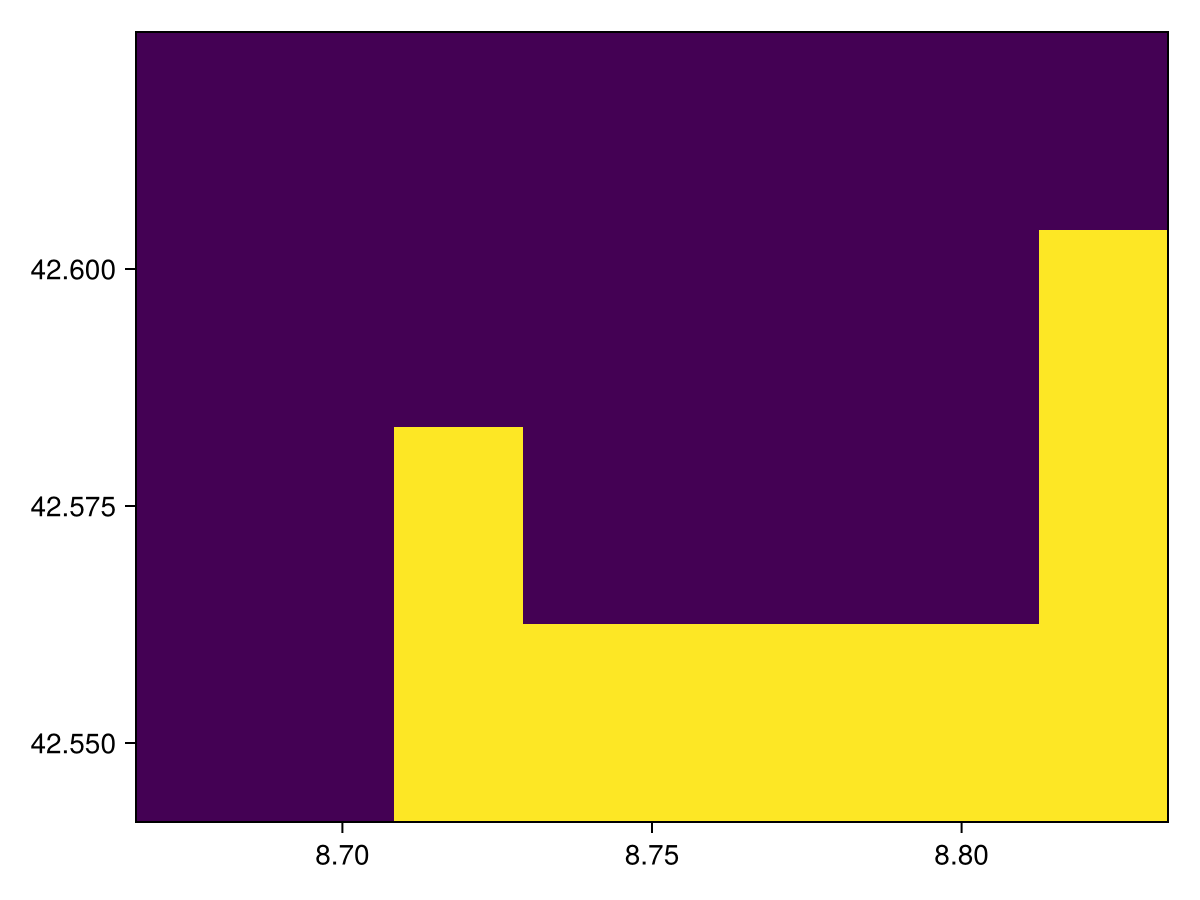

In [21]:
lon, lat, data = GeoDatasets.landseamask(; resolution = 'h', grid = 1.25)
lon_mask, lat_mask, mask = subset_mask(lon, lat, data, domain)
plot_mask(lon_mask, lat_mask, mask)

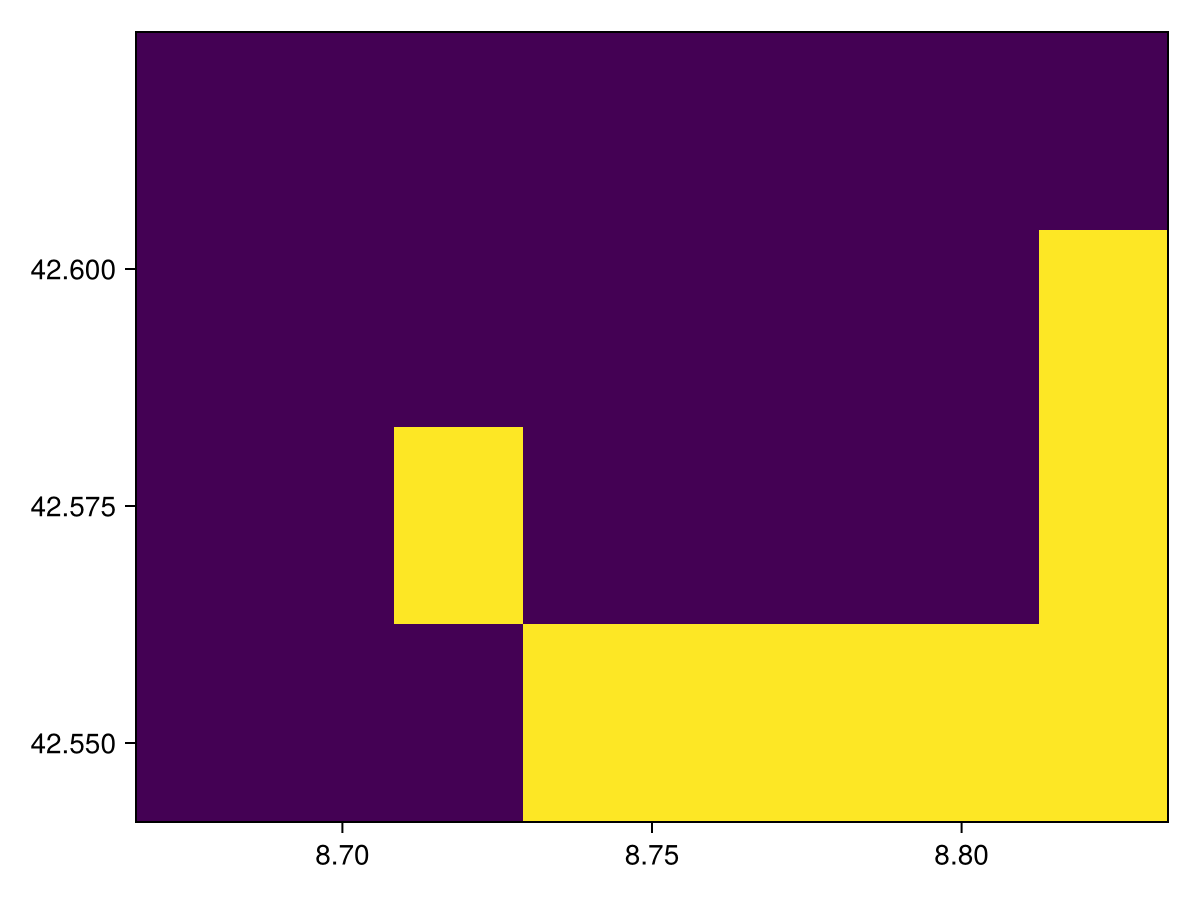

In [23]:
lon, lat, data = GeoDatasets.landseamask(; resolution = 'f', grid = 1.25)
lon_mask, lat_mask, mask = subset_mask(lon, lat, data, domain)
plot_mask(lon_mask, lat_mask, mask)

In [25]:
using Shapefile
using DataFrames
using GeoInterface
landseamask_file = "/home/ctroupin/data/Coastline/land-polygons-complete-4326/land_polygons.shp"

[ Info: Precompiling DataFrames [a93c6f00-e57d-5684-b7b6-d8193f3e46c0] (caches not reused: 1 for different dependency version already loaded, 5 for different Julia build configuration)
Precompiling packages...
  25.3 s  ✓ DataFrames (serial)
  1 dependency successfully precompiled in 25 seconds
[ Info: Precompiling StructUtilsDataFramesExt [7eb36e01-e505-53c8-b8c6-20dbe5b6b760] (caches not reused: 1 for different dependency version already loaded)
Precompiling packages...
   0.8 s  ✓ StructUtilsDataFramesExt (serial)
  1 dependency successfully precompiled in 1 seconds
[ Info: Precompiling GeometryOpsDataFramesExt [78c80550-25de-5d3e-a9d9-d8f32b5e6e66] (caches not reused: 1 for different dependency version already loaded, 2 for different Julia build configuration)
Precompiling packages...
   0.9 s  ✓ GeometryOpsDataFramesExt (serial)
  1 dependency successfully precompiled in 1 seconds


"/home/ctroupin/data/Coastline/land-polygons-complete-4326/land_polygons.shp"

In [27]:
table = Shapefile.Table(landseamask_file)
df = DataFrame(table)

subset_df = filter(
    row -> begin
        # Access the geometry column directly from the DataFrameRow
        geom = row.geometry

        # Retrieve the Minimum Bounding Rectangle (MBR)
        mbr = geom.MBR

        # Check if the polygon's bounding box fits inside your domain target coordinates
        return mbr.left <= domain[2] &&
               mbr.right >= domain[1] &&
               mbr.bottom <= domain[4] &&
               mbr.top >= domain[3]
    end,
    df,
);

In [28]:
clean_polylines = collect(skipmissing(subset_df.geometry));

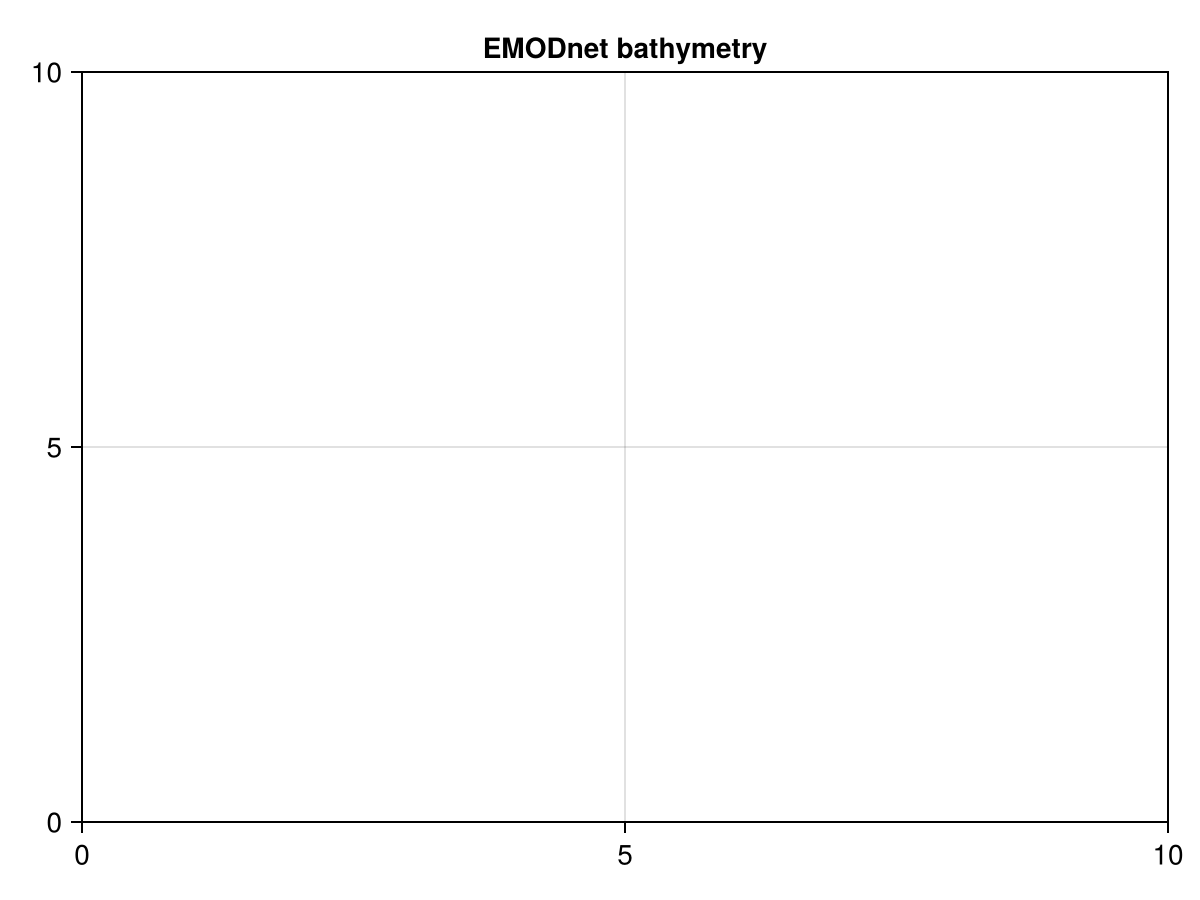

CairoMakie.Screen{IMAGE}


In [51]:
fig = Figure()
ga = Axis(fig[1, 1]; title = "EMODnet bathymetry")

for polyline in clean_polylines
    line_parts = GeoInterface.coordinates(polyline)

    for polygon in line_parts
        exterior = Point2f.(first.(polygon[1]), last.(polygon[1]))
        holes = [Point2f.(first.(ring), last.(ring)) for ring in polygon[2:end]]

        if isempty(holes)
            poly!(
                ax,
                exterior;
                color = (:steelblue, 0.5),
                strokecolor = :black,
                strokewidth = 1,
            )
        else
            poly!(
                ax,
                Polygon(exterior, holes);
                color = (:steelblue, 0.5),
                strokecolor = :black,
                strokewidth = 1,
            )
        end
    end
end
display(fig)

In [52]:
geoms = Shapefile.sh(landseamask_file)

LoadError: MethodError: no method matching shapes(::String)
The function `shapes` exists, but no method is defined for this combination of argument types.

[0mClosest candidates are:
[0m  shapes([91m::Shapefile.Handle[39m)
[0m[90m   @[39m [36mShapefile[39m [90m~/.julia/packages/Shapefile/GyofU/src/[39m[90m[4mhandle.jl:38[24m[39m
[0m  shapes([91m::Shapefile.Table[39m)
[0m[90m   @[39m [36mShapefile[39m [90m~/.julia/packages/Shapefile/GyofU/src/[39m[90m[4mtable.jl:188[24m[39m


In [53]:
using Shapefile